## Phase 3 Results
- LightGBM beats seasonal-naive by **25.6% on RMSE** (MAE 1.28 → 1.05, bias within ±3%) on a 28-day held-out window.
- Improvements are consistent across categories (Foods 25.0%, Hobbies 27.2%, Household 27.5%).
- Top features: SKU identity, rolling 7d/28d means, and `wm_yr_wk` calendar context. SNAP flags rank mid-pack — meaningful but not dominant.

In [33]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import joblib
import os
import gc
from pathlib import Path

# M5 split conventions
TRAIN_END = pd.Timestamp("2016-03-27")
VAL_END   = pd.Timestamp("2016-04-24")
TEST_END  = pd.Timestamp("2016-05-22")
HORIZON   = 28

# Paths
DATA_DIR    = Path("../data/processed")
MODEL_DIR   = Path("../models")
MODEL_DIR.mkdir(exist_ok=True, parents=True)

print("Imports OK")

Imports OK


In [34]:
features_path = DATA_DIR / "features.parquet"
assert features_path.exists(), f"Missing {features_path}. Run feature engineering first."

df = pd.read_parquet(features_path)
df = df.sort_values(["item_id", "store_id", "date"]).reset_index(drop=True)
print(f"Loaded {len(df):,} rows, dates {df['date'].min().date()} to {df['date'].max().date()}")

Loaded 31,740,090 rows, dates 2013-07-17 to 2016-05-22


In [35]:
assert "df" in dir() and isinstance(df, pd.DataFrame), "Run Cell 2 first"

train_mask = df["date"] <= TRAIN_END
val_mask   = (df["date"] > TRAIN_END) & (df["date"] <= VAL_END)
test_mask  = (df["date"] > VAL_END)   & (df["date"] <= TEST_END)

print(f"train: {train_mask.sum():,}   val: {val_mask.sum():,}   test: {test_mask.sum():,}")
# Expected test size: ~853,720 (30,490 SKUs × 28 days). If much smaller, features.parquet is incomplete.

train: 30,032,650   val: 853,720   test: 853,720


In [36]:
feature_cols = [
    "wday", "month", "year", "wm_yr_wk",
    "snap_ca", "snap_tx", "snap_wi",
    "sell_price", "price_pct_change",
    "lag_7", "lag_28", "roll7_mean", "roll28_mean", "roll7_std",
    "item_id", "store_id", "dept_id", "cat_id", "state_id",
    "event_name_1", "event_type_1",
]
cat_cols = [
    "item_id", "store_id", "dept_id", "cat_id", "state_id",
    "event_name_1", "event_type_1",
]
print(f"{len(feature_cols)} features, {len(cat_cols)} categorical")

21 features, 7 categorical


In [37]:
assert all(c in df.columns for c in feature_cols), "Some feature_cols are missing from df"

model_path = MODEL_DIR / "lgbm_v1.pkl"

if model_path.exists():
    model = joblib.load(model_path)
    print(f"Loaded trained model from {model_path}")
    print(f"  best_iteration: {model.best_iteration_}")
else:
    X_train = df.loc[train_mask, feature_cols]
    y_train = df.loc[train_mask, "units_sold"]
    X_val   = df.loc[val_mask,   feature_cols]
    y_val   = df.loc[val_mask,   "units_sold"]
    print(f"Training on {len(X_train):,} rows, validating on {len(X_val):,}")

    params = dict(
        objective="tweedie", tweedie_variance_power=1.1,
        metric="rmse",
        learning_rate=0.05, num_leaves=128,
        feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
        n_estimators=2000, verbose=-1,
    )
    model = lgb.LGBMRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        categorical_feature=cat_cols,
        callbacks=[lgb.early_stopping(50), lgb.log_evaluation(50)],
    )
    joblib.dump(model, model_path)
    print(f"Saved model to {model_path}")

    del X_train, y_train, X_val, y_val
    gc.collect()

Loaded trained model from ..\models\lgbm_v1.pkl
  best_iteration: 864


In [38]:
assert "test_mask" in dir(), "Run Cell 3 first"

# Take df rows up through the test window, but null out units_sold for the test rows
combined = df[df["date"] <= TEST_END].copy()
combined["units_sold"] = combined["units_sold"].astype("float32")
combined.loc[combined["date"] > VAL_END, "units_sold"] = np.nan

n_test = combined["units_sold"].isna().sum()
print(f"combined: {len(combined):,} rows, of which {n_test:,} are test rows (units_sold = NaN)")
assert n_test > 800_000, "Test rows missing — features.parquet doesn't cover the test window"

combined: 31,740,090 rows, of which 853,720 are test rows (units_sold = NaN)


In [39]:
def predict_recursive(model, combined_df, start_date, horizon=28,
                      feature_cols=None, cat_cols=None, verbose=True):
    """
    For each of the next `horizon` days starting at `start_date`:
      1. Recompute lag/rolling features using the current state of combined_df.
      2. Predict units_sold for that day's rows.
      3. Write predictions back into combined_df so the next day's lag features
         can see them.
    Returns a DataFrame of (item_id, store_id, date, lgbm_forecast).
    """
    df = combined_df.sort_values(["item_id", "store_id", "date"]).reset_index(drop=True).copy()
    df["units_sold"] = df["units_sold"].astype("float32")
    forecasts = []

    for h in range(horizon):
        pred_date = start_date + pd.Timedelta(days=h)
        mask = df["date"] == pred_date
        n = mask.sum()
        if n == 0:
            if verbose:
                print(f"  [skip] {pred_date.date()}: 0 rows")
            continue

        g = df.groupby(["item_id", "store_id"], observed=True)["units_sold"]
        df.loc[mask, "lag_7"]       = g.shift(7).loc[mask].astype("float32").values
        df.loc[mask, "lag_28"]      = g.shift(28).loc[mask].astype("float32").values
        df.loc[mask, "roll7_mean"]  = g.shift(1).rolling(7).mean().loc[mask].astype("float32").values
        df.loc[mask, "roll28_mean"] = g.shift(1).rolling(28).mean().loc[mask].astype("float32").values
        df.loc[mask, "roll7_std"]   = g.shift(1).rolling(7).std().loc[mask].astype("float32").values

        X = df.loc[mask, feature_cols]
        preds = np.clip(model.predict(X), 0, None).astype("float32")
        df.loc[mask, "units_sold"] = preds

        out = df.loc[mask, ["item_id", "store_id", "date"]].copy()
        out["lgbm_forecast"] = preds
        forecasts.append(out)

        if verbose:
            print(f"  [done] h={h:2d} {pred_date.date()} rows={n:,} mean_pred={preds.mean():.3f}")

    if not forecasts:
        raise RuntimeError("No forecasts produced — check that combined has test-window rows.")
    return pd.concat(forecasts, ignore_index=True)

print("Function defined")

Function defined


In [40]:
fc_path = DATA_DIR / "lgbm_forecast.parquet"

if fc_path.exists():
    lgbm_fc = pd.read_parquet(fc_path)
    print(f"Loaded {len(lgbm_fc):,} forecast rows from {fc_path}")
else:
    lgbm_fc = predict_recursive(
        model, combined,
        start_date=VAL_END + pd.Timedelta(days=1),   # 2016-05-23
        horizon=HORIZON,
        feature_cols=feature_cols,
        cat_cols=cat_cols,
    )
    lgbm_fc.to_parquet(fc_path)
    print(f"\nGenerated {len(lgbm_fc):,} forecast rows, saved to {fc_path}")

Loaded 853,720 forecast rows from ..\data\processed\lgbm_forecast.parquet


In [41]:
# Truth: actuals from the test window
truth = df.loc[test_mask, ["item_id", "store_id", "date", "units_sold"]].copy()

# Compute seasonal-naive forecast directly: today's prediction = actual 28 days ago
sn = df[["item_id", "store_id", "date", "units_sold"]].copy()
sn = sn.sort_values(["item_id", "store_id", "date"])
sn["sn_forecast"] = sn.groupby(["item_id", "store_id"], observed=True)["units_sold"].shift(28)
sn["sn_forecast"] = sn["sn_forecast"].fillna(0).clip(lower=0)
sn = sn.loc[(sn["date"] > VAL_END) & (sn["date"] <= TEST_END),
            ["item_id", "store_id", "date", "sn_forecast"]]
print(f"Seasonal-naive built: {len(sn):,} rows")

# Merge LightGBM forecast
truth = truth.merge(lgbm_fc[["item_id","store_id","date","lgbm_forecast"]],
                    on=["item_id", "store_id", "date"], how="left")
# Merge seasonal-naive forecast
truth = truth.merge(sn, on=["item_id", "store_id", "date"], how="left")

# Sanity check
missing_lgbm = truth["lgbm_forecast"].isna().sum()
missing_sn   = truth["sn_forecast"].isna().sum()
print(f"Test rows: {len(truth):,}   missing LGBM: {missing_lgbm:,}   missing naive: {missing_sn:,}")
assert missing_lgbm == 0 and missing_sn == 0, "Forecast coverage incomplete"

# Save the new baseline parquet for downstream phases (overwrites the stale one)
sn.to_parquet(DATA_DIR / "baseline_forecast.parquet")

def metrics(y, yhat, label):
    mae  = (y - yhat).abs().mean()
    rmse = np.sqrt(((y - yhat) ** 2).mean())
    bias = (yhat - y).mean()
    print(f"  {label:12s}  MAE={mae:.4f}  RMSE={rmse:.4f}  bias={bias:+.4f}")

print("\nTest-window metrics:")
metrics(truth["units_sold"], truth["sn_forecast"],   "Naive")
metrics(truth["units_sold"], truth["lgbm_forecast"], "LightGBM")

rmse_naive = np.sqrt(((truth["units_sold"] - truth["sn_forecast"]) ** 2).mean())
rmse_lgbm  = np.sqrt(((truth["units_sold"] - truth["lgbm_forecast"]) ** 2).mean())
improvement = (1 - rmse_lgbm / rmse_naive) * 100
print(f"\nLightGBM beats Naive by {improvement:.1f}% on RMSE")

Seasonal-naive built: 853,720 rows
Test rows: 853,720   missing LGBM: 0   missing naive: 0

Test-window metrics:
  Naive         MAE=1.2840  RMSE=2.8292  bias=-0.0564
  LightGBM      MAE=1.0477  RMSE=2.1038  bias=-0.0251

LightGBM beats Naive by 25.6% on RMSE


In [42]:
results = truth.rename(columns={
    "units_sold": "actual",
    "sn_forecast": "control_forecast",
    "lgbm_forecast": "treatment_forecast",
})
results.to_parquet(DATA_DIR / "forecasts.parquet")
print(f"Saved {len(results):,} rows to forecasts.parquet")
print(results.head())

Saved 853,720 rows to forecasts.parquet
       item_id store_id       date  actual  treatment_forecast  \
0  FOODS_1_001     CA_1 2016-04-25       2            0.765944   
1  FOODS_1_001     CA_1 2016-04-26       0            0.813423   
2  FOODS_1_001     CA_1 2016-04-27       0            0.812441   
3  FOODS_1_001     CA_1 2016-04-28       0            0.824354   
4  FOODS_1_001     CA_1 2016-04-29       0            0.982080   

   control_forecast  
0               2.0  
1               1.0  
2               1.0  
3               0.0  
4               4.0  


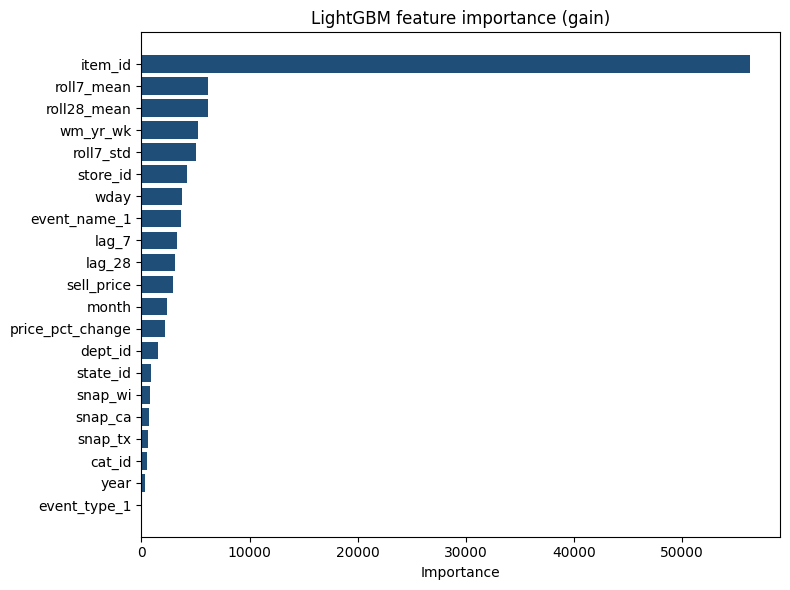

     feature  importance
      lag_28        3057
       lag_7        3306
event_name_1        3684
        wday        3734
    store_id        4217
   roll7_std        5069
    wm_yr_wk        5242
 roll28_mean        6142
  roll7_mean        6159
     item_id       56228


In [43]:
import matplotlib.pyplot as plt

imp = pd.DataFrame({
    "feature": model.feature_name_,
    "importance": model.feature_importances_,
}).sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp["feature"], imp["importance"], color="#1F4E79")
ax.set_title("LightGBM feature importance (gain)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("../docs/img/06_feature_importance.png", dpi=150)
plt.show()

print(imp.tail(10).to_string(index=False))

In [44]:
cat_lookup = df[["item_id","cat_id"]].drop_duplicates()
by_cat = (truth.merge(cat_lookup, on="item_id")
                .groupby("cat_id")
                .apply(lambda g: pd.Series({
                    "rmse_naive": np.sqrt(((g["units_sold"] - g["sn_forecast"])**2).mean()),
                    "rmse_lgbm":  np.sqrt(((g["units_sold"] - g["lgbm_forecast"])**2).mean()),
                }))
                .assign(improvement_pct=lambda x: (1 - x["rmse_lgbm"]/x["rmse_naive"])*100))
print(by_cat.round(3))

           rmse_naive  rmse_lgbm  improvement_pct
cat_id                                           
FOODS           3.501      2.627           24.977
HOBBIES         2.265      1.650           27.177
HOUSEHOLD       1.928      1.397           27.546


In [45]:
by_cat.to_csv("../data/processed/category_breakdown.csv")

<Figure size 640x480 with 0 Axes>

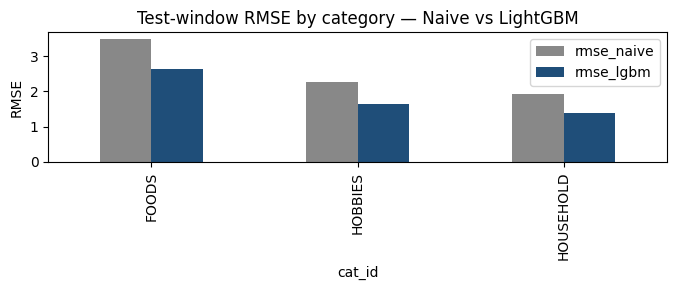

In [ ]:

plt.savefig("../docs/img/06_feature_importance.png", dpi=150, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(7, 3))
by_cat[["rmse_naive","rmse_lgbm"]].plot(kind="bar", ax=ax, color=["#888","#1F4E79"])
ax.set_title("Test-window RMSE by category — Naive vs LightGBM")
ax.set_ylabel("RMSE")
plt.tight_layout()
plt.savefig("../docs/img/07_rmse_by_category.png", dpi=150)